# MCDI500 · Avance Fase 3 — Semana 2
## Núcleo algorítmico, eficiencia y programación orientada a objetos

**Proyecto:** Análisis de distribución y concentración de matrícula de primer año de Institutos Profesionales en Chile, 2025.  
**Grupo 8:** Cristian Pérez Cortés y Claudio Navarrete Sims.  
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial, UNAB.  
**Docente:** Omar Iván Salinas Silva.  
**Fuente de información:** base INDICES Matrícula CNED suministrada para el proyecto.

La Fase 3 **no vuelve a limpiar el Excel**: transforma la implementación de F2 en un núcleo modular y comprueba que produce exactamente el mismo resultado. Después compara dos alternativas para agrupar la matrícula, con mediciones controladas de tiempo y memoria.

**Pregunta del proyecto:** ¿Cómo se distribuye y concentra la matrícula de primer año de los Institutos Profesionales en Chile durante 2025, según institución, región y área de conocimiento?

## 1. Preparación del entorno y vínculo con F2

El entorno debe instalarse previamente desde `requirements.txt`. No se ejecutan comandos `pip install` dentro del notebook. La ruta de la raíz se determina de forma portable, y la semilla 42 evita diferencias en cálculos estocásticos de F2.

La **entrada principal** de F3 es el extracto IP/2025 generado en F2; el CSV procesado se utiliza como referencia adicional. Si no están presentes, corresponde ejecutar F2 y conservar el Excel original en `data/raw`.

In [1]:
from pathlib import Path
import json, sys, subprocess
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name in {"F1", "F2", "F3", "F4"} else Path.cwd()
if str(RAIZ) not in sys.path: sys.path.insert(0, str(RAIZ))
from src.cned_pipeline import preparar_fase2, validar_fase2, concentracion_matricula
from src.f3_transformaciones import TransformadorCNED, DepuradorEstructura, ImputadorSelectivo, ConstructorVariables
from src.f3_pipeline import PipelineCNED
from src.f3_medicion import agrupar_por_bucle, agrupar_vectorizado, comprobar_mismos_resultados, comparar_algoritmos
from src.f3_recursion import aplanar_metadatos

np.random.seed(42)
DIR_DATOS = RAIZ / 'data'
DIR_DOCS = RAIZ / 'docs'
DIR_EVIDENCIA = RAIZ / 'evidencias'
for d in (DIR_DOCS, DIR_EVIDENCIA): d.mkdir(parents=True,exist_ok=True)
print('Intérprete:',sys.executable)
print('Python:',sys.version.split()[0], '| Pandas:',pd.__version__,'| NumPy:',np.__version__)
print('Herramientas:',{x:metadata.version(x) for x in ['nbformat','nbclient','openpyxl','lxml','pytest']})
print('Carpeta raíz:',RAIZ)

Intérprete: /opt/pyvenv/bin/python
Python: 3.13.5 | Pandas: 2.2.3 | NumPy: 2.3.5
Herramientas: {'nbformat': '5.10.4', 'nbclient': '0.10.4', 'openpyxl': '3.1.5', 'lxml': '6.1.1', 'pytest': '9.0.2'}
Carpeta raíz: /mnt/data/MCDI500_CNED_Trabajo_F3/MCDI500_CNED


### 1.1 Carga de las salidas de F2

Se comprueba que ambos archivos existen y que el conjunto pertenece a IP/2025. La referencia conserva **4.731 registros**, 27 instituciones y el total observado de matrícula. No se imputa ninguna columna de matrícula: los ceros son valores válidos.

In [2]:
RUTA_ORIGEN = DIR_DATOS / 'interim' / 'ip_2025_origen_filtrado.csv'
RUTA_F2 = DIR_DATOS / 'processed' / 'matricula_ip_2025_procesada_v3.csv'
for p in (RUTA_ORIGEN,RUTA_F2):
    if not p.exists():
        raise FileNotFoundError(f'Falta {p}. Ejecute primero F2 con el Excel original.')
origen = pd.read_csv(RUTA_ORIGEN,encoding='utf-8-sig',low_memory=False)
procesado_f2 = pd.read_csv(RUTA_F2,encoding='utf-8-sig',low_memory=False)
assert origen.shape == (4731,62)
assert procesado_f2.shape == (4731,68)
assert origen['Año'].eq(2025).all() and origen['Tipo Institución'].eq('I.P.').all()
assert origen['Nombre Institución'].nunique()==27
assert int(origen['Matrícula Primer Año'].sum())==137481
assert int(origen['Matrícula Total'].sum())==439607
print('Origen IP/2025:',origen.shape,'| Procesado F2:',procesado_f2.shape)
display(procesado_f2[['Nombre Institución','Nombre Region','Area Conocimiento','Matrícula Primer Año']].head())

Origen IP/2025: (4731, 62) | Procesado F2: (4731, 68)


,Nombre Institución,Nombre Region,Area Conocimiento,Matrícula Primer Año
0,IP AGRARIO ADOLFO MATTHEI,Región de Los Lagos,"Agricultura, Silvicultura, Pesca y Veterinaria",72
1,IP AGRARIO ADOLFO MATTHEI,Región de Los Lagos,"Agricultura, Silvicultura, Pesca y Veterinaria",41
2,IP AGRARIO ADOLFO MATTHEI,Región de Los Lagos,"Agricultura, Silvicultura, Pesca y Veterinaria",69
3,IP AGRARIO ADOLFO MATTHEI,Región de Los Lagos,"Agricultura, Silvicultura, Pesca y Veterinaria",41
4,IP INACAP,Región de Antofagasta,Administración y Comercio,29


## 2. De F2 a clases: herencia, encapsulamiento y polimorfismo

Las transformaciones se organizaron en tres componentes con responsabilidad única:

| Clase | Responsabilidad | Funciones de F2 que reutiliza |
|---|---|---|
| `DepuradorEstructura` | Normaliza valores ausentes y columnas eliminables | `depurar_estructura` |
| `ImputadorSelectivo` | Selecciona estrategia con validación y crea estimaciones identificadas | `comparar_imputaciones`, `imputar_variable` |
| `ConstructorVariables` | Produce categorías, variables derivadas y controles | `crear_categorias_matricula` |

Las tres heredan de `TransformadorCNED`, que establece los métodos `ajustar()` y `transformar()` y protege su estado `_ajustado` y `_parametros`. La composición `PipelineCNED` invoca la **misma interfaz** para los tres objetos (polimorfismo). **Patrón adoptado:** Template Method, porque el orden de validación y copia defensiva es común, mientras las operaciones específicas cambian por clase. Además, la selección documentada de métodos de imputación funciona como una estrategia configurable. No se introducen patrones sin necesidad analítica.

In [3]:
pasos = [DepuradorEstructura(), ImputadorSelectivo(semilla=42), ConstructorVariables()]
for paso in pasos:
    assert isinstance(paso, TransformadorCNED)
    print(type(paso).__name__, 'hereda de TransformadorCNED:', isinstance(paso,TransformadorCNED))

# Caso de excepción: no se puede transformar sin aprendizaje previo.
try:
    PipelineCNED().transformar(origen)
except RuntimeError as exc:
    print('Excepción controlada:',exc)
else:
    raise AssertionError('El pipeline aceptó ejecutar antes de ajustar')

DepuradorEstructura hereda de TransformadorCNED: True
ImputadorSelectivo hereda de TransformadorCNED: True
ConstructorVariables hereda de TransformadorCNED: True
Excepción controlada: PipelineCNED: primero debe llamar ajustar()


### 2.1 Ejecución modular

Se ajustan y ejecutan las tres etapas sobre el mismo conjunto descriptivo de F2. No se entrena un modelo predictivo ni se afirma capacidad de generalización: el objetivo académico es demostrar la **equivalencia de procesamiento**. Si posteriormente se desarrollara un modelo supervisado, las imputaciones, cuantiles y escaladores tendrían que aprenderse exclusivamente del conjunto de entrenamiento.

In [4]:
pipeline = PipelineCNED()
pipeline.ajustar(origen)
procesado_poo = pipeline.transformar(origen)
display(pipeline.resumen())
print('Resultado F3:',procesado_poo.shape)
assert int(procesado_poo['Matrícula Primer Año'].sum())==137481
assert int(procesado_poo['Matrícula Total'].sum())==439607

,paso,transformador,ajustado,parametros
0,1,DepuradorEstructura,True,"columnas_vacias, columnas_excluidas_por_umbral"
1,2,ImputadorSelectivo,True,"Valor de arancel, Valor de matrícula, Valor de..."
2,3,ConstructorVariables,True,"variables_requeridas, maximo_matricula_primer_..."


Resultado F3: (4731, 68)


## 3. Prueba principal: ¿la arquitectura POO preserva F2?

La guía del profesor señala esta prueba como el puente fundamental entre F2 y F3. Usamos `pd.testing.assert_frame_equal(..., check_exact=True)` para comparar **todas las celdas, columnas, tipos y orden**, no solo dimensiones. Se realiza también una comparación de los CSV exportados. No se modifica la fuente CNED.

In [5]:
referencia_f2, auditoria_f2 = preparar_fase2(origen)
pd.testing.assert_frame_equal(referencia_f2, procesado_poo, check_exact=True)
resumen_validacion = validar_fase2(origen, procesado_poo, auditoria_f2)
assert (procesado_poo['Matrícula Primer Año'] == origen['Matrícula Primer Año']).all()
assert (procesado_poo['Matrícula Total'] == origen['Matrícula Total']).all()

# Comprobar también la salida CSV guardada por F2 con normalización de lectura.
RUTA_F3 = DIR_DATOS / 'processed' / 'matricula_ip_2025_procesada_f3.csv'
procesado_poo.to_csv(RUTA_F3,index=False,encoding='utf-8-sig')
f3_leido=pd.read_csv(RUTA_F3,encoding='utf-8-sig',low_memory=False)
pd.testing.assert_frame_equal(procesado_f2, f3_leido, check_exact=True)

veredicto = {
    'filas':len(procesado_poo),'columnas':procesado_poo.shape[1],
    'matricula_primer_anio':int(procesado_poo['Matrícula Primer Año'].sum()),
    'matricula_total':int(procesado_poo['Matrícula Total'].sum()),
    'equivalencia_dataframe_exacto': True,'equivalencia_csv': True,
    'fuente_original_modificada': False,
}
(DIR_EVIDENCIA/'f3_equivalencia_f2.json').write_text(json.dumps(veredicto,ensure_ascii=False,indent=2),encoding='utf-8')
print('Equivalencia F2 = F3 demostrada:',veredicto)
display(pd.DataFrame([resumen_validacion]))

Equivalencia F2 = F3 demostrada: {'filas': 4731, 'columnas': 68, 'matricula_primer_anio': 137481, 'matricula_total': 439607, 'equivalencia_dataframe_exacto': True, 'equivalencia_csv': True, 'fuente_original_modificada': False}


,filas_sin_perdidas,columnas_salida,filas_anomalia_temporal,cero_primer_anio_preservados,nulos_originales_preservados_por_columna,desgloses_matricula_consistentes
0,4731,68,1,1576,True,True


## 4. Eficiencia del núcleo: dos algoritmos equivalentes

Se compara la suma de matrícula de primer año por institución mediante dos alternativas:

- **A (repetición por grupo):** se filtran todas las filas para cada institución. Aproximación temporal **O(n·k)**, donde *n* es el número de filas y *k* el número de instituciones.
- **B (Pandas `groupby`):** se agrupa la columna una vez, con costo esperado **O(n)** más ordenación de *k* resultados (**O(k log k)**).

Antes de medir se exige igualdad exacta de resultados. Se usan `timeit.repeat` (tres rondas de tres ejecuciones) y `tracemalloc` (pico de memoria atribuible a Python). Para observar el crecimiento, se mide en 250, 1.000 y 4.731 registros. Estos tiempos dependen del equipo y del entorno.

In [6]:
assert comprobar_mismos_resultados(procesado_poo)
agrupacion_bucle=agrupar_por_bucle(procesado_poo)
agrupacion_vectorizada=agrupar_vectorizado(procesado_poo)
pd.testing.assert_series_equal(agrupacion_bucle,agrupacion_vectorizada,check_exact=True,check_names=False)
print('Agrupaciones iguales:',len(agrupacion_bucle),'instituciones; total',int(agrupacion_bucle.sum()))
bench = comparar_algoritmos(procesado_poo,tamanos=(250,1000,4731),repeticiones=3,numero=3)
bench.to_csv(DIR_EVIDENCIA/'f3_benchmarks.csv',index=False,encoding='utf-8-sig')
display(bench)
total=bench.query('filas==4731').set_index('algoritmo')
rapidez=float(total.loc['bucle_por_grupo','tiempo_minimo_ms']/total.loc['pandas_groupby','tiempo_minimo_ms'])
print(f'Para 4.731 filas, groupby fue {rapidez:.1f} veces más rápido en esta ejecución.')
print('Memoria pico, MiB:',total['memoria_pico_mib'].round(4).to_dict())

Agrupaciones iguales: 27 instituciones; total 137481


,filas,algoritmo,rondas,repeticiones_por_ronda,tiempo_minimo_ms,tiempo_mediana_ms,memoria_pico_mib,grupos,equivalencia_validada
0,250,bucle_por_grupo,3,3,0.535,0.542,0.0108,2,True
1,250,pandas_groupby,3,3,0.418,0.430,0.0176,2,True
2,1000,bucle_por_grupo,3,3,1.693,1.816,0.0340,8,True
3,1000,pandas_groupby,3,3,0.493,0.530,0.0584,8,True
4,4731,bucle_por_grupo,3,3,9.236,9.329,0.1356,27,True
5,4731,pandas_groupby,3,3,0.928,0.960,0.2383,27,True


Para 4.731 filas, groupby fue 10.0 veces más rápido en esta ejecución.
Memoria pico, MiB: {'bucle_por_grupo': 0.1356, 'pandas_groupby': 0.2383}


### 4.1 Interpretación

Los métodos entregan exactamente la misma matrícula por institución. El bucle realiza búsquedas repetidas para *k* grupos; `groupby` agrupa de forma más eficiente. Elegimos `groupby` para la implementación analítica por su menor tiempo esperado sobre conjuntos mayores. El resultado de memoria puede ser distinto (las estructuras internas de Pandas requieren memoria adicional); se informa sin concluir que una alternativa domina en todas las dimensiones. La memoria de `tracemalloc` **no mide toda la memoria nativa de NumPy/Pandas**, por lo que se interpreta como aproximación parcial.

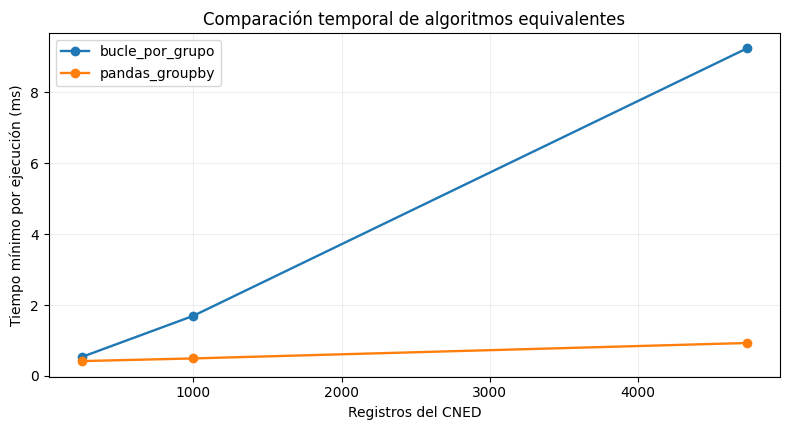

In [7]:
fig,ax=plt.subplots(figsize=(8,4.4))
for nombre,sub in bench.groupby('algoritmo'):
    ax.plot(sub['filas'],sub['tiempo_minimo_ms'],marker='o',linewidth=1.7,label=nombre)
ax.set(xlabel='Registros del CNED',ylabel='Tiempo mínimo por ejecución (ms)',title='Comparación temporal de algoritmos equivalentes')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(DIR_EVIDENCIA/'f3_comparacion_tiempos.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Recursividad y límites de aplicación

El conjunto de matrícula es tabular: aplicar recursión a la agrupación sería innecesario. Sin embargo, los metadatos del proyecto tienen niveles anidados, por lo que implementamos una función recursiva para generar claves trazables. Incluye caso base (valor simple) y recursivo (diccionario). **No sustituye el procesamiento tabular**, para el cual la división funcional y `groupby` son más adecuados.

In [8]:
metadata={
  'proyecto': {'nombre':'Matrícula IP 2025','fases':{'F1':'definición','F2':'datos','F3':'POO'}},
  'fuente': {'institucion':'CNED','año':2025},
  'evidencia': {'filas':len(procesado_poo),'instituciones':origen['Nombre Institución'].nunique()}
}
plano=aplanar_metadatos(metadata)
assert plano['proyecto.fases.F3']=='POO'
assert plano['evidencia.filas']==4731
print('Metadatos recursivos:',plano)
(DIR_DOCS/'f3_metadatos_aplanados.json').write_text(json.dumps(plano,ensure_ascii=False,indent=2),encoding='utf-8')

Metadatos recursivos: {'proyecto.nombre': 'Matrícula IP 2025', 'proyecto.fases.F1': 'definición', 'proyecto.fases.F2': 'datos', 'proyecto.fases.F3': 'POO', 'fuente.institucion': 'CNED', 'fuente.año': 2025, 'evidencia.filas': 4731, 'evidencia.instituciones': 27}


257

## 6. Pruebas normales, límite y excepciones

Se verifican casos específicos (grupo único, error por columna inexistente, transformación sin ajuste) y la regresión completa automatizada de las fases anteriores y actual. La batería completa se ejecuta externamente con pytest para evitar duplicar en el kernel la extracción de un Excel grande; su registro queda en evidencias/ para revisión académica y en GitHub.

In [9]:
# Caso normal: dos instituciones con conteo conocido.
sintetico = pd.DataFrame({'Nombre Institución':['A','A','B'], 'Matrícula Primer Año':[3,2,0]})
assert agrupar_vectorizado(sintetico).to_dict()=={'A':5,'B':0}
# Caso límite: solo una institución.
assert len(agrupar_vectorizado(sintetico.iloc[:2]))==1
# Excepción: columna inexistente.
try:
    agrupar_vectorizado(sintetico,'Campo inexistente')
except KeyError:
    print('Columna inexistente: error esperado y controlado')
else:
    raise AssertionError('No se controló la columna inexistente')

# La batería completa se ejecuta por separado para no duplicar la extracción
# del XLSX de 58 MB dentro de un kernel Jupyter de memoria limitada.
# Ver tests/test_f3_poo.py y tests/test_f3_integracion.py.
REGISTRO_PRUEBAS = DIR_EVIDENCIA / 'f3_resultados_pruebas.txt'
if REGISTRO_PRUEBAS.exists():
    print('Registro de pruebas externas:')
    print(REGISTRO_PRUEBAS.read_text(encoding='utf-8')[-1500:])
else:
    print('Pruebas completas: ejecutar desde terminal python -m pytest -q tests')

Columna inexistente: error esperado y controlado
Registro de pruebas externas:
........................................                                 [100%]
40 passed in 29.40s



## 7. Arquitectura, trazabilidad y GitHub

Los módulos `src/f3_transformaciones.py`, `src/f3_pipeline.py`, `src/f3_medicion.py` y `src/f3_recursion.py` concentran el código funcional. Los notebooks solo orquestan, explican y presentan evidencias. Los commits de los integrantes deberán registrarse con su autor real y fecha efectiva.

La implementación orientada a objetos **no modifica la Fase 2**, lo que facilita comprobar regresiones y continuar hacia la fase de visualización F4.

In [10]:
componentes=pd.DataFrame([
    {'componente':'TransformadorCNED','archivo':'src/f3_transformaciones.py','responsabilidad':'contrato base, validación y estado'},
    {'componente':'DepuradorEstructura','archivo':'src/f3_transformaciones.py','responsabilidad':'calidad de datos, reuso de F2'},
    {'componente':'ImputadorSelectivo','archivo':'src/f3_transformaciones.py','responsabilidad':'estrategias y banderas de imputación'},
    {'componente':'ConstructorVariables','archivo':'src/f3_transformaciones.py','responsabilidad':'variables analíticas derivadas'},
    {'componente':'PipelineCNED','archivo':'src/f3_pipeline.py','responsabilidad':'composición polimórfica'},
    {'componente':'comparar_algoritmos','archivo':'src/f3_medicion.py','responsabilidad':'timeit, memoria y equivalencia'},
    {'componente':'aplanar_metadatos','archivo':'src/f3_recursion.py','responsabilidad':'recursión de estructura anidada'},
])
display(componentes)
componentes.to_csv(DIR_DOCS/'f3_arquitectura.csv',index=False,encoding='utf-8-sig')

def git_lectura(*args):
    try:
        resultado=subprocess.run(['git',*args],cwd=RAIZ,capture_output=True,text=True,timeout=6)
        return resultado.stdout.strip() if resultado.returncode==0 else 'No disponible en esta copia'
    except (FileNotFoundError,subprocess.TimeoutExpired):
        return 'Git no disponible'
print('Rama Git:',git_lectura('branch','--show-current'))
print('Commit:',git_lectura('rev-parse','--short','HEAD'))

,componente,archivo,responsabilidad
0,TransformadorCNED,src/f3_transformaciones.py,"contrato base, validación y estado"
1,DepuradorEstructura,src/f3_transformaciones.py,"calidad de datos, reuso de F2"
2,ImputadorSelectivo,src/f3_transformaciones.py,estrategias y banderas de imputación
3,ConstructorVariables,src/f3_transformaciones.py,variables analíticas derivadas
4,PipelineCNED,src/f3_pipeline.py,composición polimórfica
5,comparar_algoritmos,src/f3_medicion.py,"timeit, memoria y equivalencia"
6,aplanar_metadatos,src/f3_recursion.py,recursión de estructura anidada


Rama Git: No disponible en esta copia
Commit: No disponible en esta copia


## 8. Resultados y reflexión técnica

El núcleo POO reproduce el procesamiento F2 y conserva los resultados CNED. La comparación de implementaciones identifica una alternativa de menor costo temporal para el agrupamiento institucional, con equivalencia comprobada. El principal aprendizaje es que **organizar el código no debe cambiar los datos ni los indicadores**; las mejoras se aceptan después de verificar exactitud, mantenibilidad y rendimiento.

**Limitaciones:** estudio descriptivo de 2025, sin inferencias causales ni modelación predictiva; las medidas de tiempo dependen del equipo; `tracemalloc` no captura toda la memoria nativa. La composición del Grupo 8 con dos integrantes requiere confirmación formal del docente, pues la guía general indica 3–4.

**Bibliografía y fuentes:** guía del docente (Sumativa 2 F3, 2026), práctica del docente de Semana 2 (2026); Python Software Foundation, documentación de `timeit`, `abc` y `tracemalloc`; pandas Development Team, documentación de `groupby` y `assert_frame_equal`; McKinney (2022), *Python for Data Analysis*, 3.ª ed. Las citas completas figuran en el informe técnico.

**Referencias de implementación:** este notebook sigue la estructura académica presentada en el repositorio docente de Semana 2, pero el código de las clases y los resultados han sido construidos para las variables CNED; no se reutiliza el dataset de ejemplo sobre accidentes cerebrovasculares.